# 06 · Research synthesis and limitations

A transparent separation between observed current EV use, reported consideration, exploratory associations, and predictive modeling. This notebook produces a publication-friendly sample-sensitivity panel; legal/regulatory material remains contextual rather than a measured predictor.

## Environment

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'ev_research').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.ev_research.data import load_survey, sample_audit, cleaning_audit
from src.ev_research.config import FIGURES, TABLES, FEATURE_SETS, SOURCE_INDEX
from src.ev_research.plotting_style import apply_style
from src.ev_research.statistics import prevalence_table, assumptions_audit, fisher_associations, sensitivity_table
from src.ev_research.figures import *
apply_style()
raw, unique, eligible = load_survey()
print(f'Raw: {len(raw)} | Distinct: {len(unique)} | Eligible: {len(eligible)}')
def show_figure(path, width=1150):
    """Display the exact saved PNG (also exported as vector SVG)."""
    assert path.exists(), f'Missing figure: {path}'
    display(Image(filename=str(path), width=width))


Raw: 105 | Distinct: 92 | Eligible: 62


## Outcome-specific evidence, not a transition forecast

Given \(15/60\) current-use responses and \(34/59\) consideration responses, we cannot infer a national adoption gap or estimate a causal intervention effect. The surveys were not a longitudinal panel.

,outcome,positive,negative,n,rate,wilson_95_low,wilson_95_high
0,ev_use,15,45,60,0.250000,0.157765,0.372321
1,ev_consideration,34,25,59,0.576271,0.449345,0.693873


,analysis,outcome,n,positive,rate
0,deduplicated_main,ev_use,60,15,0.250000
1,deduplicated_main,ev_consideration,59,34,0.576271
2,exact_duplicates_retained,ev_use,69,22,0.318841
3,exact_duplicates_retained,ev_consideration,67,42,0.626866
4,current_nonadopters_only,ev_consideration,44,19,0.431818


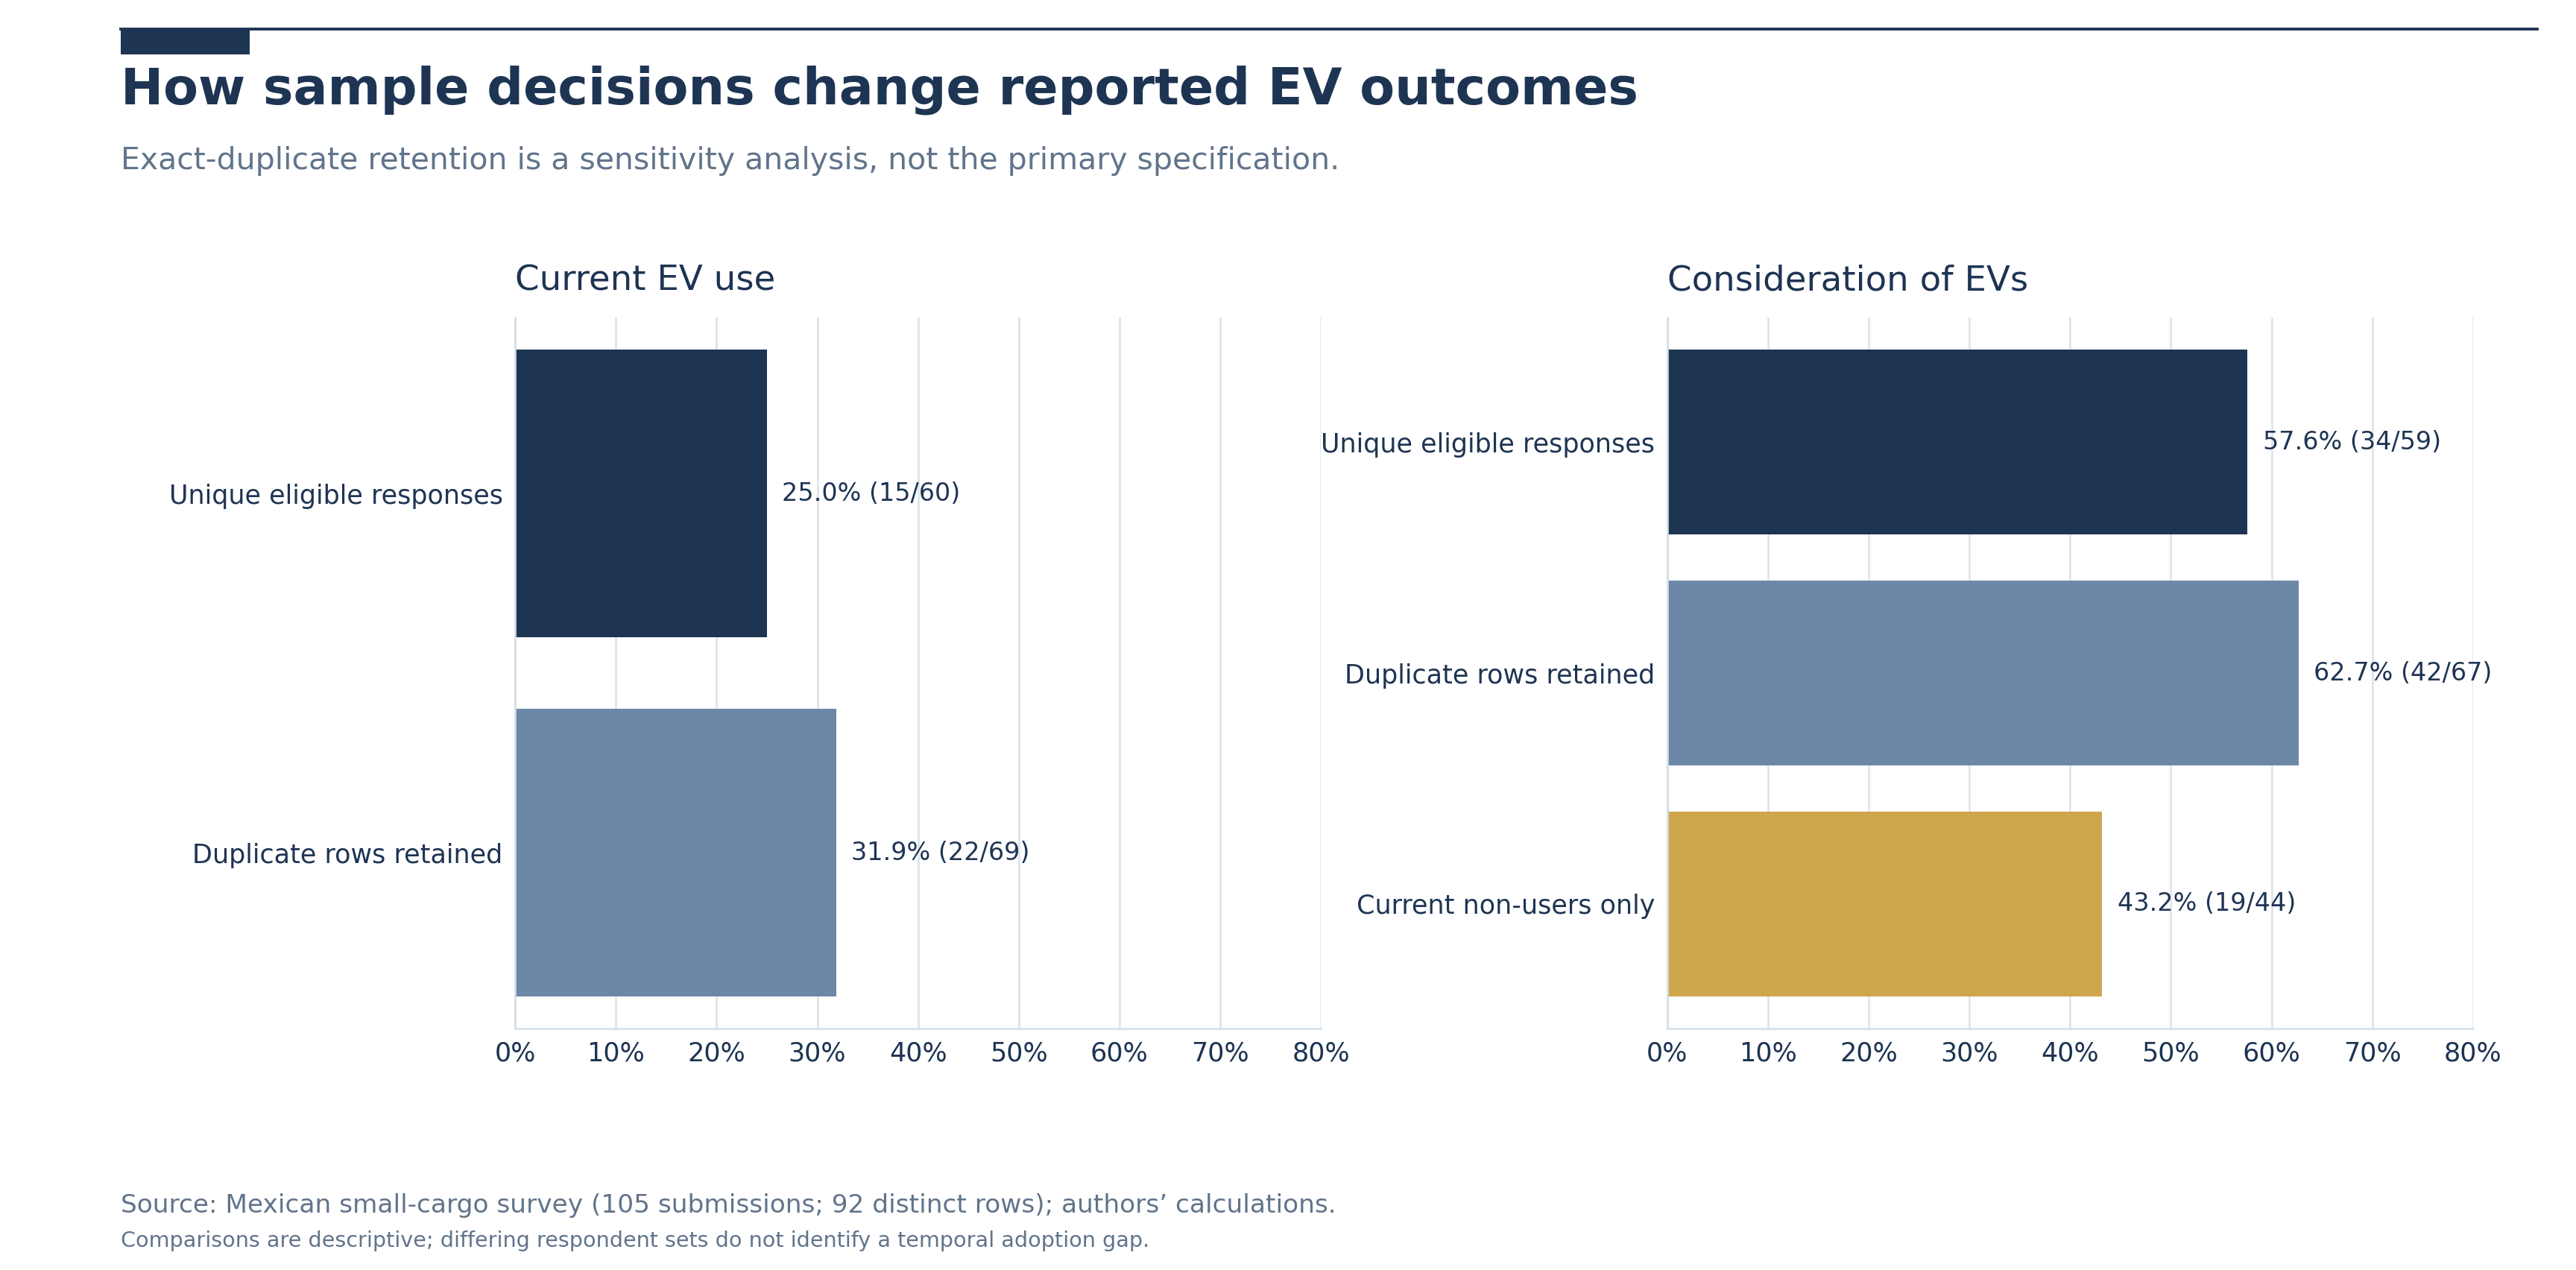

In [2]:
display(prevalence_table(eligible))
display(sensitivity_table(raw,eligible,SOURCE_INDEX))
plot_sample_sensitivity(eligible,raw,SOURCE_INDEX)
show_figure(FIGURES/'06_synthesis'/'01_duplicate_and_nonadopter_sensitivity.png')

## Comparison across model specifications

Any summary of the saved results must report outcome, feature scenario, metric, seed design and uncertainty type. Do not interpret differences smaller than observed seed variability as robust algorithm superiority.

In [3]:
model_summaries=[]
for target in ['ev_use','ev_consideration']:
    model_summaries.append(pd.read_csv(TABLES/f'{target}_summary.csv'))
ranking=pd.concat(model_summaries,ignore_index=True)
display(ranking.sort_values(['outcome','scenario','balanced_accuracy_mean'],ascending=[True,True,False]).groupby(['outcome','scenario']).head(3))

,outcome,scenario,model,n,seeds,balanced_accuracy_mean,roc_auc_mean,average_precision_mean,f1_mean,recall_mean,specificity_mean,brier_score_mean,balanced_accuracy_sd,roc_auc_sd,average_precision_sd,f1_sd,recall_sd,specificity_sd,brier_score_sd
12,ev_consideration,fleet_baseline,linear_svm,59,3,0.583529,0.681373,0.755861,0.646904,0.647059,0.520000,NaN,0.052260,0.044264,0.060876,0.044426,0.050943,0.069282,NaN
13,ev_consideration,fleet_baseline,logistic_l2,59,3,0.573725,0.655098,0.739549,0.634364,0.627451,0.520000,0.234432,0.069664,0.068099,0.077287,0.047593,0.033962,0.105830,0.016595
11,ev_consideration,fleet_baseline,lightgbm,59,3,0.552745,0.621176,0.725645,0.589944,0.558824,0.546667,0.241393,0.022091,0.021396,0.027814,0.036290,0.050943,0.023094,0.005928
18,ev_consideration,operational_extended,logistic_l2,59,3,0.558039,0.624314,0.750379,0.577232,0.529412,0.586667,0.239242,0.048565,0.073174,0.046533,0.049960,0.050943,0.046188,0.017844
19,ev_consideration,operational_extended,random_forest,59,3,0.546471,0.573333,0.701703,0.566208,0.519608,0.573333,0.245029,0.018961,0.068489,0.068256,0.025888,0.044927,0.061101,0.014967
16,ev_consideration,operational_extended,lightgbm,59,3,0.545098,0.584706,0.699332,0.548857,0.490196,0.600000,0.247118,0.024708,0.055842,0.071878,0.035053,0.044927,0.040000,0.015572
3,ev_use,fleet_baseline,logistic_l2,60,3,0.677778,0.703704,0.464815,0.515543,0.622222,0.733333,0.216852,0.019245,0.012194,0.042396,0.024022,0.038490,0.076980,0.002862
4,ev_use,fleet_baseline,random_forest,60,3,0.666667,0.710123,0.472358,0.501316,0.600000,0.733333,0.207200,0.094933,0.065026,0.020215,0.120527,0.133333,0.058794,0.007671
1,ev_use,fleet_baseline,lightgbm,60,3,0.651852,0.679506,0.393297,0.486382,0.688889,0.614815,0.236123,0.057018,0.103312,0.065802,0.062098,0.101835,0.105018,0.030993
9,ev_use,operational_extended,random_forest,60,3,0.692593,0.695802,0.560407,0.538309,0.577778,0.807407,0.195775,0.055925,0.048468,0.025515,0.075360,0.076980,0.067890,0.007520


## Research boundaries and next evidence needs

1. **Sample:** non-random, small, self-reported; duplicate handling materially changes proportions.
2. **Operations:** mixed units and incomplete route/cost answers preclude an empirically validated TCO threshold or depot charging feasibility calculation.
3. **Models:** no independent external validation, and no causal identification of policies.
4. **Policy context:** legal regulations affect interpretation but were not measured as firm-level treatment variables.
5. **Publication:** figures are descriptive and the notebook/source data should be shared according to respondent confidentiality and research agreements.